### A8q — frozen Option A (quat checkpoint)

Plot-only. Loads `results_a8q.npz` + `results_a8q.json`. Does **not** train and does **not** overwrite `option_a_a8q.pth`.

A8q is the defended one-model row: quat beats `insfilterMARG`, ATE ties GPS-vel, RTE beats GPS-vel. The A8 ATE snapshot is shown only as the trade-off we rejected (better path, dead compass).

**Restart + Run All.**

In [1]:
import os, json
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

HERE = os.getcwd()
if not os.path.exists(os.path.join(HERE, "results_a8q.npz")):
    HERE = os.path.join(HERE, "option_a")
NPZ = os.path.join(HERE, "results_a8q.npz")
JS = os.path.join(HERE, "results_a8q.json")
OUT = os.path.join(HERE, "a8q_highlights")
os.makedirs(OUT, exist_ok=True)

d = np.load(NPZ)
meta = json.load(open(JS))
pos_te, pos_a, pos_e, pos_g = d["pos_te"], d["pos_hat"], d["pos_ekf"], d["pos_gps"]
q_te, q_a, q_e = d["q_te"], d["q_hat"], d["q_ekf"]
v_hat, v_gt, v_gps = d["v_hat"], d["v_gt"], d["v_gps"]

TEST_T0 = 121.0
t1 = TEST_T0 + np.arange(len(pos_te))
tq = TEST_T0 + np.arange(len(q_te)) * 0.1

C_A, C_E, C_G, C_GT = "#c0392b", "#2980b9", "#7f8c8d", "#2c3e50"
print("A8q artifacts", NPZ)
print("TEST 1s", pos_te.shape, "quat 0.1s", q_te.shape)


A8q artifacts c:\Users\noxuz\OneDrive\Documentos\000000LETESIS\sensor_fusion_thesis\option_a\results_a8q.npz
TEST 1s (21, 3) quat 0.1s (210, 4)


In [2]:
def q_normalize(q, eps=1e-8):
    return q / (np.linalg.norm(q, axis=-1, keepdims=True) + eps)

def q_ang_deg(qa, qb):
    d = np.clip(np.abs((q_normalize(qa) * q_normalize(qb)).sum(-1)), -1, 1)
    return np.degrees(2 * np.arccos(d))

def ate_rte(est, ref, hop=1.0, sec=1.0):
    ate = float(np.sqrt(((est - ref) ** 2).sum(1).mean()))
    w = max(int(round(sec / hop)), 1)
    rel = [
        np.linalg.norm((est[i + w] - est[i]) - (ref[i + w] - ref[i]))
        for i in range(0, len(est) - w, max(w // 2, 1))
    ]
    return ate, float(np.mean(rel)) if rel else float("nan")

ate_a, rte_a = ate_rte(pos_a, pos_te)
ate_e, rte_e = ate_rte(pos_e, pos_te)
ate_g, rte_g = ate_rte(pos_g, pos_te)
quat_a = float(q_ang_deg(q_a, q_te).mean())
quat_e = float(q_ang_deg(q_e, q_te).mean())
err_a = np.linalg.norm(pos_a - pos_te, axis=1)
err_e = np.linalg.norm(pos_e - pos_te, axis=1)
err_g = np.linalg.norm(pos_g - pos_te, axis=1)
qerr_a = q_ang_deg(q_a, q_te)
qerr_e = q_ang_deg(q_e, q_te)

print(f"{'':16} {'ATE':>8} {'RTE':>8} {'quat':>8}")
print(f"{'A8q (frozen)':16} {ate_a:8.3f} {rte_a:8.3f} {quat_a:7.2f}°")
print(f"{'insfilterMARG':16} {ate_e:8.3f} {rte_e:8.3f} {quat_e:7.2f}°")
print(f"{'GPS-vel int':16} {ate_g:8.3f} {rte_g:8.3f} {'—':>8}")
print(f"json A8q     {meta['A']['ate_m']:.3f} / {meta['A']['rte_m']:.3f} / {meta['A']['quat_mean_deg']:.2f}°")
print(f"A8 ATE-ckpt  {meta['ATE_ckpt']['ate_m']:.3f} / {meta['ATE_ckpt']['rte_m']:.3f} / {meta['ATE_ckpt']['quat_mean_deg']:.2f}°  (rejected)")


                      ATE      RTE     quat
A8q (frozen)        1.119    0.312    4.95°
insfilterMARG       0.775    0.201    7.46°
GPS-vel int         1.103    0.451        —
json A8q     1.119 / 0.312 / 4.95°
A8 ATE-ckpt  0.926 / 0.323 / 14.28°  (rejected)


#### Why this snapshot

Same A8 training run, two checkpoints. The ATE file is the better path and a dead compass. A8q is the one-model row we keep.

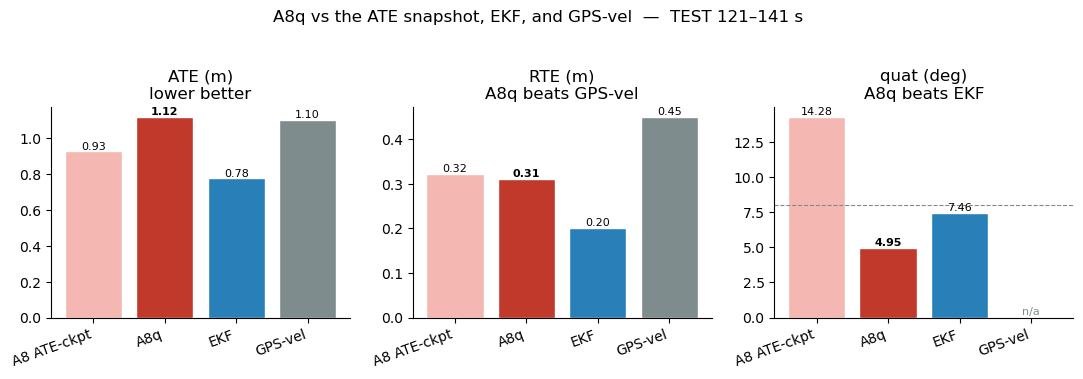

In [3]:
ate_ck = meta["ATE_ckpt"]
q_ck = meta["quat_ckpt"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
bars = [
    ("ATE (m)\nlower better", [ate_ck["ate_m"], q_ck["ate_m"], ate_e, ate_g], None),
    ("RTE (m)\nlower better", [ate_ck["rte_m"], q_ck["rte_m"], rte_e, rte_g], None),
    ("quat (deg)\nlower better", [ate_ck["quat_mean_deg"], q_ck["quat_mean_deg"], quat_e, np.nan], 8),
]
names = ["A8 ATE-ckpt", "A8q", "EKF", "GPS-vel"]
cols = ["#f5b7b1", C_A, C_E, C_G]
for ax, (title, vals, hline) in zip(axes, bars):
    x = np.arange(len(names))
    v = np.array(vals, dtype=float)
    ax.bar(x, np.nan_to_num(v, nan=0.0), color=cols, edgecolor="white")
    for i, y in enumerate(v):
        if np.isnan(y):
            ax.text(i, 0.05, "n/a", ha="center", va="bottom", fontsize=8, color=C_G)
        else:
            ax.text(i, y, f"{y:.2f}", ha="center", va="bottom", fontsize=8,
                    fontweight="bold" if i == 1 else "normal")
    if hline is not None:
        ax.axhline(hline, color=C_G, ls="--", lw=0.8, label="EKF 7.46°")
    ax.set_xticks(x, names, rotation=20, ha="right")
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[1].set_title("RTE (m)\nA8q beats GPS-vel")
axes[2].set_title("quat (deg)\nA8q beats EKF")
fig.suptitle("A8q vs the ATE snapshot, EKF, and GPS-vel  —  TEST 121–141 s", y=1.04)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "01_scorecard.png"), dpi=150, bbox_inches="tight")
plt.show()


#### TEST path

21 one-second hops. A8q tracks the quadcopter; the EKF stays closer in position because it sees GPS LLA. A8q’s claim is the shape (RTE) and the attitude, not a lower ATE than the EKF.

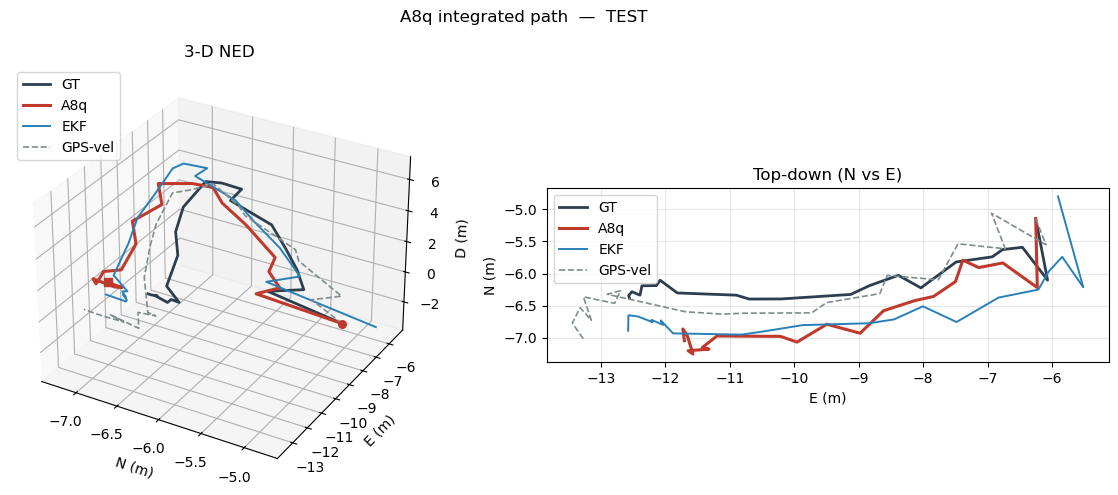

In [4]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121, projection="3d")
ax.plot(*pos_te.T, color=C_GT, lw=2.0, label="GT")
ax.plot(*pos_a.T, color=C_A, lw=2.2, label="A8q")
ax.plot(*pos_e.T, color=C_E, lw=1.4, label="EKF")
ax.plot(*pos_g.T, color=C_G, lw=1.2, ls="--", label="GPS-vel")
ax.scatter(*pos_a[0], color=C_A, s=30, zorder=5)
ax.scatter(*pos_a[-1], color=C_A, s=30, marker="s", zorder=5)
ax.set_xlabel("N (m)"); ax.set_ylabel("E (m)"); ax.set_zlabel("D (m)")
ax.set_title("3-D NED")
ax.legend(loc="upper left")

ax2 = fig.add_subplot(122)
ax2.plot(pos_te[:, 1], pos_te[:, 0], color=C_GT, lw=2.0, label="GT")
ax2.plot(pos_a[:, 1], pos_a[:, 0], color=C_A, lw=2.2, label="A8q")
ax2.plot(pos_e[:, 1], pos_e[:, 0], color=C_E, lw=1.4, label="EKF")
ax2.plot(pos_g[:, 1], pos_g[:, 0], color=C_G, lw=1.2, ls="--", label="GPS-vel")
ax2.set_xlabel("E (m)"); ax2.set_ylabel("N (m)")
ax2.set_title("Top-down (N vs E)")
ax2.set_aspect("equal", adjustable="box")
ax2.legend()
ax2.grid(True, alpha=0.3)
fig.suptitle("A8q integrated path  —  TEST")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "02_path.png"), dpi=150, bbox_inches="tight")
plt.show()


#### Errors vs time

Position error grows (ATE 0.74 m in the first 10 s → 1.41 m in the last 10 s). Quaternion stays below the EKF for most of the holdout — that is the highlight.

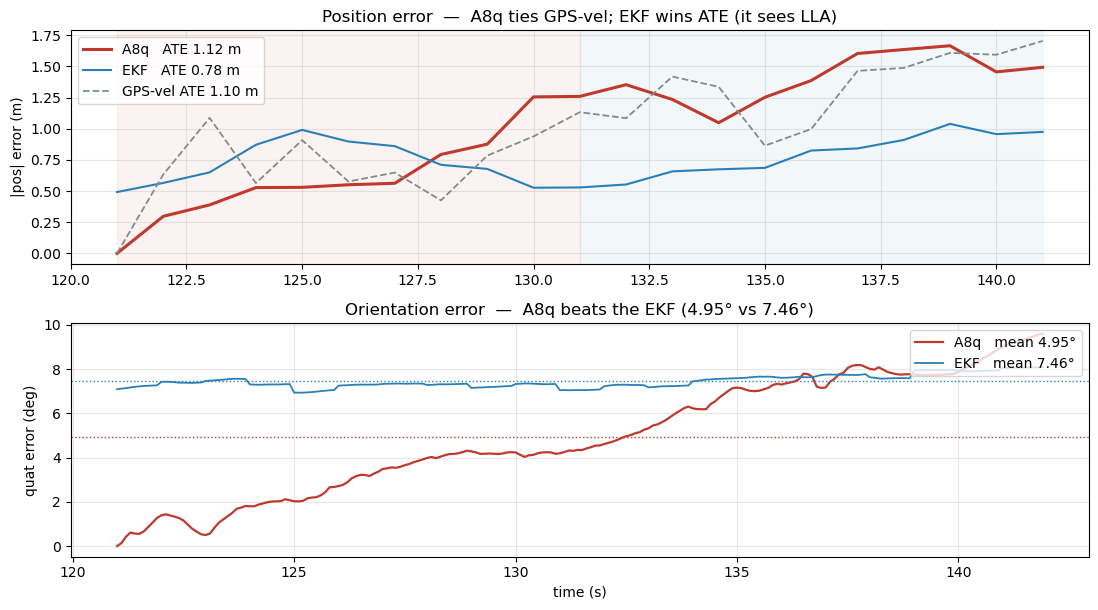

first 10 s ATE  A8q 0.74 m   EKF 0.73 m
last  10 s ATE  A8q 1.41 m   EKF 0.80 m


In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=False)
ax1.plot(t1, err_a, color=C_A, lw=2.2, label=f"A8q   ATE {ate_a:.2f} m")
ax1.plot(t1, err_e, color=C_E, lw=1.5, label=f"EKF   ATE {ate_e:.2f} m")
ax1.plot(t1, err_g, color=C_G, lw=1.3, ls="--", label=f"GPS-vel ATE {ate_g:.2f} m")
ax1.axvspan(t1[0], t1[0] + 10, color=C_A, alpha=0.06)
ax1.axvspan(t1[-1] - 10, t1[-1], color=C_E, alpha=0.06)
ax1.set_ylabel("|pos| error (m)")
ax1.set_title("Position error  —  A8q ties GPS-vel; EKF wins ATE (it sees LLA)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

ax2.plot(tq, qerr_a, color=C_A, lw=1.6, label=f"A8q   mean {quat_a:.2f}°")
ax2.plot(tq, qerr_e, color=C_E, lw=1.3, label=f"EKF   mean {quat_e:.2f}°")
ax2.axhline(quat_a, color=C_A, ls=":", lw=1)
ax2.axhline(quat_e, color=C_E, ls=":", lw=1)
ax2.set_xlabel("time (s)")
ax2.set_ylabel("quat error (deg)")
ax2.set_title("Orientation error  —  A8q beats the EKF (4.95° vs 7.46°)")
ax2.legend(loc="upper right")
ax2.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "03_errors.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"first 10 s ATE  A8q {meta['A']['first_10s']['ate_m']:.2f} m   EKF {meta['EKF']['first_10s']['ate_m']:.2f} m")
print(f"last  10 s ATE  A8q {meta['A']['last_10s']['ate_m']:.2f} m   EKF {meta['EKF']['last_10s']['ate_m']:.2f} m")


#### Velocity (why ATE walks)

Residual head: $\hat v = v_\mathrm{gps} + \delta v$. A ~0.09 m/s bias still walks about a meter over the 20 s TEST — that is the ATE gap to the EKF, not a broken integrator.

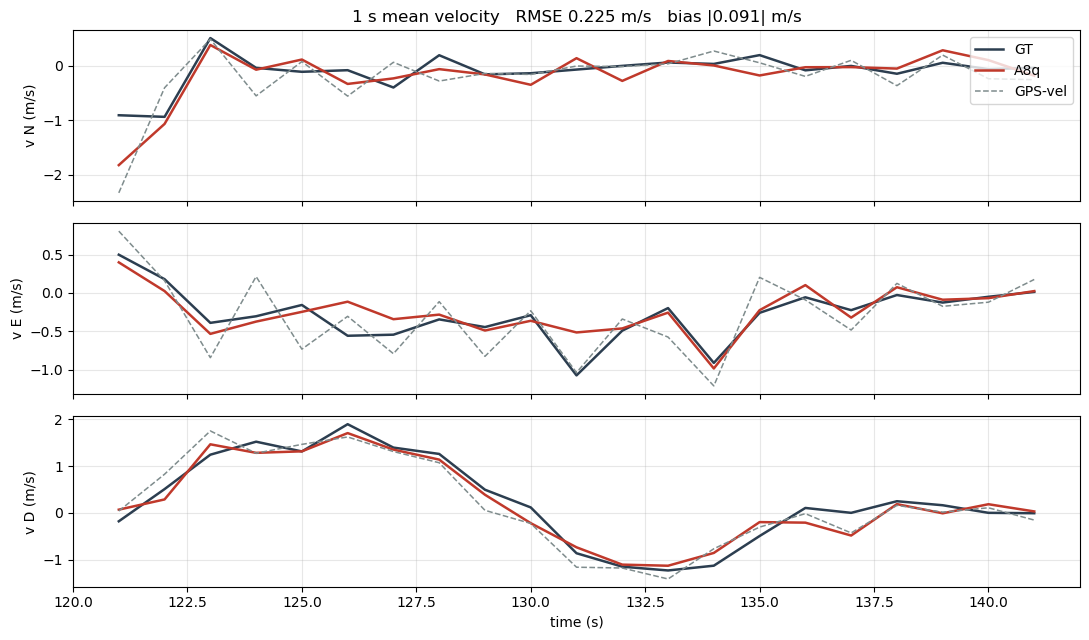

bias NED [-0.07605065  0.0342022  -0.03592668] |bias| 0.09079767763614655


In [6]:
labs = ["N", "E", "D"]
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
bias = (v_hat - v_gt).mean(0)
rmse = float(np.sqrt(((v_hat - v_gt) ** 2).mean()))
for i, ax in enumerate(axes):
    ax.plot(t1, v_gt[:, i], color=C_GT, lw=1.8, label="GT" if i == 0 else None)
    ax.plot(t1, v_hat[:, i], color=C_A, lw=1.8, label="A8q" if i == 0 else None)
    ax.plot(t1, v_gps[:, i], color=C_G, lw=1.1, ls="--", label="GPS-vel" if i == 0 else None)
    ax.set_ylabel(f"v {labs[i]} (m/s)")
    ax.grid(True, alpha=0.3)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time (s)")
axes[0].set_title(f"1 s mean velocity   RMSE {rmse:.3f} m/s   bias |{np.linalg.norm(bias):.3f}| m/s")
fig.tight_layout()
fig.savefig(os.path.join(OUT, "04_velocity.png"), dpi=150, bbox_inches="tight")
plt.show()
print("bias NED", bias, "|bias|", float(np.linalg.norm(bias)))


#### Per-axis position and the headline numbers

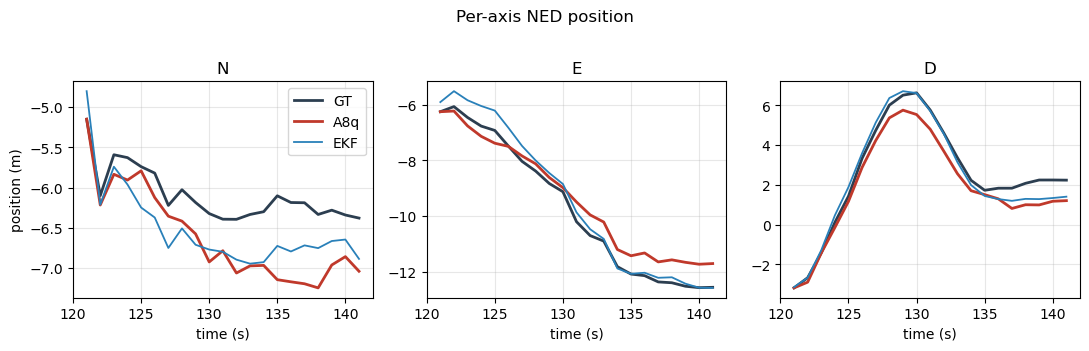

A8q  ATE 1.119 m   RTE 0.312 m   quat 4.95°
EKF  ATE 0.775 m   RTE 0.201 m   quat 7.46°
GPS  ATE 1.103 m   RTE 0.451 m
wrote c:\Users\noxuz\OneDrive\Documentos\000000LETESIS\sensor_fusion_thesis\option_a\a8q_highlights


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t1, pos_te[:, i], color=C_GT, lw=2.0, label="GT")
    ax.plot(t1, pos_a[:, i], color=C_A, lw=2.0, label="A8q")
    ax.plot(t1, pos_e[:, i], color=C_E, lw=1.3, label="EKF")
    ax.set_title(labs[i])
    ax.set_xlabel("time (s)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("position (m)")
axes[0].legend()
fig.suptitle("Per-axis NED position", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(OUT, "05_axes.png"), dpi=150, bbox_inches="tight")
plt.show()

print("A8q  ATE {:.3f} m   RTE {:.3f} m   quat {:.2f}°".format(ate_a, rte_a, quat_a))
print("EKF  ATE {:.3f} m   RTE {:.3f} m   quat {:.2f}°".format(ate_e, rte_e, quat_e))
print("GPS  ATE {:.3f} m   RTE {:.3f} m".format(ate_g, rte_g))
print("wrote", OUT)
